# Predicción de pérdida de envíos con un sistema neuro-difuso (ANFIS)

Este notebook entrena un **sistema de inferencia difusa adaptativo** (ANFIS, *Adaptive Network-based Fuzzy Inference System*) de tipo Takagi-Sugeno para predecir `is_lost` **al crear el envío, antes del despacho**. Es la contraparte difusa de `rna_shipment_loss.ipynb`: comparte con él la limpieza, las variables, la partición temporal, el protocolo de semillas y las métricas, de modo que los dos modelos sean comparables fila a fila.

Lo que se hereda del notebook RNA se copia tal cual y se marca como tal; la evidencia que justifica cada decisión de limpieza (fugas de la etiqueta, `DATEPARAMETER`, madurez de la etiqueta, artefactos de valores faltantes, `LG_REGION`) vive en ese notebook y no se repite aquí.

Lo nuevo es la parte difusa:

1. **Codificación**: un sistema difuso solo entiende entradas numéricas, así que cada variable categórica se convierte en su tasa de pérdida, estimada **solo con entrenamiento** y fuera de pliegue para no filtrar la etiqueta de cada fila a su propia variable.
2. **Arquitectura ANFIS**: funciones de pertenencia gaussianas entrenables por regla y variable, t-norma producto, normalización de los grados de activación y consecuentes lineales de primer orden. La salida es un logit que pasa por una sigmoide y se entrena con entropía cruzada binaria.
3. **Inicialización**: los centros de las reglas salen de *fuzzy c-means* sobre el entrenamiento, de modo que cada regla nace cubriendo una región real del espacio de entrada.
4. **Selección**: el número de reglas se elige por PR-AUC de **validación**, nunca de prueba; después se repite el entrenamiento con cinco semillas y se reporta media y desviación.

Los puntajes están en la escala de la muestra caso-control (~31 % de pérdidas), nunca son probabilidades de producción; la única lectura operativa es la proyección a la prevalencia real de la sección 9.

## 1. Configuración

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupKFold

DATA_PATH = "../dataset.parquet"
LABEL = "is_lost"
GROUP = "SHIPMENT_ID"
RANDOM_STATE = 42
N_SEEDS = int(os.environ.get("ANFIS_N_SEEDS", 5))
SEEDS = [RANDOM_STATE + offset for offset in range(N_SEEDS)]
# Épocas máximas por entrenamiento; la parada temprana por PR-AUC de validación
# suele detenerlo antes. Una prueba rápida puede bajarlo.
MAX_EPOCHS = int(os.environ.get("ANFIS_MAX_EPOCHS", 60))
PATIENCE = 8
BATCH_SIZE = 2048
LEARNING_RATE = 5e-3
# Cantidades de reglas candidatas; se elige una sola por validación.
RULE_GRID = [int(r) for r in os.environ.get("ANFIS_RULE_GRID", "8,16,32,64").split(",")]
# Carpeta donde se exportan las figuras. Es una subcarpeta propia para no
# reemplazar las del notebook RNA; una prueba rápida debe apuntar a otro lugar.
FIGURES_DIR = os.environ.get("ANFIS_FIGURES_DIR", "../informe/figuras/anfis")

# Mismos parámetros de limpieza, partición y evaluación que el notebook RNA.
MATURITY_RATIO = 0.5
MIN_HOLDOUT_SHARE = 0.10
RANKING_FRACTIONS = [0.01, 0.05, 0.10, 0.20]
REAL_PREVALENCE = 0.001

torch.set_num_threads(max(1, os.cpu_count() - 1))
DEVICE = torch.device("cpu")
print(f"torch {torch.__version__}, hilos: {torch.get_num_threads()}, semillas: {SEEDS}, reglas candidatas: {RULE_GRID}")

# Paleta heredada del notebook RNA (ver allí la justificación de cada color).
ML_YELLOW = "#FFE600"
ML_BLUE = "#3483FA"
ML_RED = "#F23D4F"
ML_INK = "#333333"
ML_NEUTRAL = "#EDEDED"
ML_SURFACE = "#FFFFFF"
COLOR_NOT_LOST = ML_BLUE
COLOR_LOST = ML_RED
COLOR_REFERENCE = ML_INK
DIVERGING_CMAP = LinearSegmentedColormap.from_list("mercadolibre_diverging", [ML_RED, ML_NEUTRAL, ML_BLUE])

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": ML_SURFACE,
        "axes.facecolor": ML_SURFACE,
        "axes.edgecolor": ML_NEUTRAL,
        "grid.color": ML_NEUTRAL,
        "text.color": ML_INK,
        "axes.labelcolor": ML_INK,
        "xtick.color": ML_INK,
        "ytick.color": ML_INK,
        "axes.titleweight": "bold",
    },
)


def finish_figure(fig, export_as, top=0.95):
    """Ajusta el diseño, agrega la franja amarilla de marca y exporta la figura."""
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.add_artist(
        Rectangle((0, 0.98), 1, 0.02, transform=fig.transFigure, facecolor=ML_YELLOW, edgecolor="none")
    )
    os.makedirs(FIGURES_DIR, exist_ok=True)
    fig.savefig(os.path.join(FIGURES_DIR, f"{export_as}.png"), dpi=300, bbox_inches="tight")


def seed_everything(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

torch 2.10.0, hilos: 14, semillas: [42, 43, 44, 45, 46], reglas candidatas: [8, 16, 32, 64]


## 2. Datos, limpieza y variables (heredados del notebook RNA)

Las listas de columnas y la función `preprocess` son una copia literal de `rna_shipment_loss.ipynb`, sección 3. Cambiarlas aquí sin cambiarlas allí rompería la comparabilidad entre los dos modelos; si hace falta un cambio, va primero en el notebook RNA y después se copia.

In [2]:
raw = pd.read_parquet(DATA_PATH)
raw["DATEPARAMETER"] = pd.to_datetime(raw["DATEPARAMETER"])
raw["date_status_0"] = pd.to_datetime(raw["date_status_0"])
print(f"filas crudas: {len(raw):,}, columnas: {raw.shape[1]}, tasa de pérdida: {raw[LABEL].mean():.3f}")

filas crudas: 262,317, columnas: 58, tasa de pérdida: 0.243


In [3]:
LEAKAGE_COLUMNS = [
    "CAUSA_BPP",
    "L1_CAUSA_BPP",
    "L2_CAUSA_BPP",
    "DATE_BPP",
    "BPP_CASHOUT_USD",
    "CLASSIFICATION_LM",
    "SUBSTATUS_CLASIFICATION",
    "F_CLASIFICATION",
    "F_CLASIFICATION_STD",
]
MISSINGNESS_ARTIFACT_COLUMNS = ["PESO_TOTAL_KG", "DIM_MAX_CM", "VALOR_TOTAL_USD", "CANTIDAD_ITEMS"]
TIMELINE_COLUMNS = (
    [f"status_{i}" for i in range(11)] + [f"date_status_{i}" for i in range(1, 11)]
)
DATE_LEAK_COLUMNS = ["DATEPARAMETER"]
CONSTANT_COLUMNS = ["PAIS", "TOTALGMV", "CANT_BULTOS"]
REDUNDANT_COLUMNS = ["LG_FACILITY_NAME", "ORD_CATEGORY_ID_L1"]
IDENTIFIER_COLUMNS = ["SHP_SHIPMENT_ID", "ITE_ITEM_ID", "ITE_ITEM_DESC"]
ROUTE_COLUMNS = ["FUE_AVION"]
PROVENANCE_COLUMNS = ["source_file", "batch_num"]
TAXONOMY_ARTIFACT_COLUMNS = ["LG_REGION"]
DATE_COLUMN = "date_status_0"

CATEGORICAL_FEATURES = [
    "PICKING_TYPE",
    "SHP_LG_FACILITY_ID",
    "DOM_DOMAIN_ID",
    "ORD_CATEGORY_NAME_L1",
    "BRAND_NAME",
    "TIPO_BULKY",
]
NUMERIC_FEATURES = [
    "PESO_TOTAL_KG",
    "DIM_MAX_CM",
    "VALOR_TOTAL_USD",
    "CANTIDAD_ITEMS",
    "RATIO_SVC_MES_ANTERIOR",
    "ES_BULKY",
]
DERIVED_FEATURES = ["day_of_week"]
FEATURE_COLUMNS = CATEGORICAL_FEATURES + NUMERIC_FEATURES + DERIVED_FEATURES
print(f"cantidad de variables: {len(FEATURE_COLUMNS)}")

DROPPED_COLUMNS = (
    LEAKAGE_COLUMNS
    + TIMELINE_COLUMNS
    + DATE_LEAK_COLUMNS
    + CONSTANT_COLUMNS
    + REDUNDANT_COLUMNS
    + IDENTIFIER_COLUMNS
    + ROUTE_COLUMNS
    + PROVENANCE_COLUMNS
    + TAXONOMY_ARTIFACT_COLUMNS
)
accounted_for = set(CATEGORICAL_FEATURES + NUMERIC_FEATURES) | set(DROPPED_COLUMNS) | {LABEL, GROUP, DATE_COLUMN}
assert accounted_for == set(raw.columns), sorted(set(raw.columns) - accounted_for)

cantidad de variables: 13


In [4]:
DAY_NAMES = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]


def preprocess(raw: pd.DataFrame) -> pd.DataFrame:
    """Copia literal de `preprocess` del notebook RNA: variables + LABEL + GROUP."""
    frame = raw.copy()
    print(f"filas antes de cualquier filtro: {len(frame):,}")

    artifact_null = frame[MISSINGNESS_ARTIFACT_COLUMNS + [DATE_COLUMN]].isna().any(axis=1)
    frame = frame.loc[~artifact_null]
    print(f"filas tras eliminar los artefactos de valores faltantes: {len(frame):,}")

    month = frame[DATE_COLUMN].dt.to_period("M")
    month_stats = frame.groupby(month)[LABEL].agg(["nunique", "mean"])
    valid_months = list(month_stats.index[month_stats["nunique"] == 2])

    maturity_floor = MATURITY_RATIO * month_stats.loc[valid_months, "mean"].median()
    immature_months = []
    while valid_months and month_stats.loc[valid_months[-1], "mean"] < maturity_floor:
        immature_months.insert(0, valid_months.pop())

    frame = frame.loc[month.isin(valid_months)]
    print(f"meses válidos (ambas clases presentes y etiqueta madura): {[str(m) for m in valid_months]}")
    print(f"meses finales descartados por etiqueta inmadura: {[str(m) for m in immature_months]}")
    print(f"filas tras restringir a los meses válidos: {len(frame):,}")

    frame["TIPO_BULKY"] = frame["TIPO_BULKY"].fillna("NONE")
    frame["day_of_week"] = pd.Categorical(
        frame[DATE_COLUMN].dt.dayofweek.map(dict(enumerate(DAY_NAMES))),
        categories=DAY_NAMES,
        ordered=True,
    )
    for column in CATEGORICAL_FEATURES:
        frame[column] = frame[column].astype("category")

    return frame[FEATURE_COLUMNS + [LABEL, GROUP]]


clean = preprocess(raw)
clean.shape

filas antes de cualquier filtro: 262,317
filas tras eliminar los artefactos de valores faltantes: 260,104
meses válidos (ambas clases presentes y etiqueta madura): ['2025-09', '2025-10', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03']
meses finales descartados por etiqueta inmadura: ['2026-04']
filas tras restringir a los meses válidos: 165,002


(165002, 15)

## 3. Partición temporal (heredada del notebook RNA)

Misma regla: los meses más antiguos de `date_status_0` entrenan, los más recientes validan y prueban, con los meses elegidos desde los datos (`MIN_HOLDOUT_SHARE`). Como todas las filas de un envío comparten `date_status_0`, ningún `SHIPMENT_ID` cae en dos particiones, y se verifica. A diferencia del notebook RNA, aquí se conserva aparte la clave de grupo del entrenamiento: la codificación de la sección 4 la necesita.

In [5]:
def take_latest_months(available, month_share, min_share):
    """Retira de `available` los meses más recientes hasta cubrir al menos `min_share` de las filas."""
    taken = []
    while available and month_share.loc[taken].sum() < min_share:
        taken.insert(0, available.pop())
    return taken


split_month = raw.loc[clean.index, DATE_COLUMN].dt.to_period("M")
month_share = split_month.value_counts(normalize=True).sort_index()

available_months = list(month_share.index)
test_months = take_latest_months(available_months, month_share, MIN_HOLDOUT_SHARE)
val_months = take_latest_months(available_months, month_share, MIN_HOLDOUT_SHARE)
train_months = available_months
assert train_months and val_months and test_months

train = clean.loc[split_month.isin(train_months)]
val = clean.loc[split_month.isin(val_months)]
test = clean.loc[split_month.isin(test_months)]
assert len(train) + len(val) + len(test) == len(clean)
assert max(train_months) < min(val_months) and max(val_months) < min(test_months)

train_groups, val_groups, test_groups = set(train[GROUP]), set(val[GROUP]), set(test[GROUP])
assert not (train_groups & val_groups)
assert not (train_groups & test_groups)
assert not (val_groups & test_groups)

split_summary = pd.DataFrame(
    [
        {
            "particion": name,
            "meses": f"{min(months)} a {max(months)}",
            "filas": len(part),
            "proporcion_filas": len(part) / len(clean),
            "envios": part[GROUP].nunique(),
            "tasa_positivos": part[LABEL].mean(),
        }
        for name, part, months in [
            ("entrenamiento", train, train_months),
            ("validación", val, val_months),
            ("prueba", test, test_months),
        ]
    ]
).set_index("particion")

# La clave de grupo del entrenamiento se conserva para la codificación fuera de pliegue.
train_group_key = train[GROUP].to_numpy()
train = train.drop(columns=GROUP)
val = val.drop(columns=GROUP)
test = test.drop(columns=GROUP)
split_summary.round(3)

,meses,filas,proporcion_filas,envios,tasa_positivos
particion,,,,,
entrenamiento,2025-09 a 2026-01,125082,0.758,112303,0.390
validación,2026-02 a 2026-02,18831,0.114,17297,0.316
prueba,2026-03 a 2026-03,21089,0.128,19506,0.312


## 4. Codificación de las variables para el sistema difuso

Una función de pertenencia gaussiana necesita una entrada numérica sobre la que medir "cerca de" y "lejos de". Las seis categóricas (y el día de la semana) no lo son, así que se convierten en su **tasa de pérdida suavizada**:

$$\tilde{x}_c = \frac{n_c \, \bar{y}_c + m \, \bar{y}}{n_c + m}$$

donde $n_c$ y $\bar{y}_c$ son la cantidad de filas y la tasa de pérdida de la categoría $c$ en entrenamiento, $\bar{y}$ la tasa global de entrenamiento y $m$ el peso del previo: una categoría con pocas filas queda cerca de la tasa global en lugar de memorizar sus pocos casos. Las categorías no vistas en entrenamiento reciben $\bar{y}$.

Dos fugas que esta codificación evitaría mal si se hiciera a la ligera, y cómo se cierran:

- **Hacia validación y prueba**: las tasas se estiman solo con entrenamiento. Validación y prueba se codifican con esas tasas, sin mirar su etiqueta.
- **Dentro del entrenamiento**: si la tasa de una categoría se calcula con las mismas filas que luego se entrenan, la etiqueta de cada fila se filtra a su propia variable (una categoría con una sola fila perdida tendría tasa 1). Por eso el entrenamiento se codifica **fuera de pliegue**: la fila de cada pliegue usa tasas calculadas con los otros pliegues. Los pliegues se arman por `SHIPMENT_ID`, porque los artículos de un mismo envío comparten etiqueta y categorías y se filtrarían entre sí.

Las numéricas con cola larga (`PESO_TOTAL_KG`, `DIM_MAX_CM`, `VALOR_TOTAL_USD`, `CANTIDAD_ITEMS`) pasan por $\log(1 + x)$, para que una gaussiana pueda cubrirlas sin que un puñado de valores extremos la estire. Los pocos nulos que quedan en las numéricas se rellenan con la mediana de entrenamiento. Al final todo se estandariza con media y desviación de entrenamiento, para que las gaussianas de todas las variables vivan en la misma escala.

In [6]:
LOG_NUMERIC_FEATURES = ["PESO_TOTAL_KG", "DIM_MAX_CM", "VALOR_TOTAL_USD", "CANTIDAD_ITEMS"]
ENCODED_CATEGORICAL_FEATURES = CATEGORICAL_FEATURES + DERIVED_FEATURES
TARGET_ENCODING_PRIOR_WEIGHT = 20
ENCODING_FOLDS = 5


class FuzzyEncoder:
    """Convierte la tabla del modelo en una matriz numérica estandarizada, ajustada solo con entrenamiento."""

    def __init__(self, prior_weight=TARGET_ENCODING_PRIOR_WEIGHT):
        self.prior_weight = prior_weight
        self.feature_names = ENCODED_CATEGORICAL_FEATURES + NUMERIC_FEATURES

    def _rates(self, column: pd.Series, label: pd.Series) -> pd.Series:
        stats = label.groupby(column.astype(object), observed=True).agg(["sum", "count"])
        return (stats["sum"] + self.prior_weight * self.prior) / (stats["count"] + self.prior_weight)

    def _raw_matrix(self, frame: pd.DataFrame, encodings: dict) -> pd.DataFrame:
        parts = {}
        for feature in ENCODED_CATEGORICAL_FEATURES:
            parts[feature] = frame[feature].astype(object).map(encodings[feature]).fillna(self.prior).astype(float)
        for feature in NUMERIC_FEATURES:
            values = frame[feature].astype(float).fillna(self.medians[feature])
            parts[feature] = np.log1p(values.clip(lower=0)) if feature in LOG_NUMERIC_FEATURES else values
        return pd.DataFrame(parts, index=frame.index)[self.feature_names]

    def fit_transform_train(self, frame: pd.DataFrame, group_key: np.ndarray) -> np.ndarray:
        label = frame[LABEL]
        self.prior = float(label.mean())
        self.medians = {feature: float(frame[feature].astype(float).median()) for feature in NUMERIC_FEATURES}
        # Tasas con todo el entrenamiento: las que verán validación y prueba.
        self.encodings = {feature: self._rates(frame[feature], label) for feature in ENCODED_CATEGORICAL_FEATURES}

        # Entrenamiento codificado fuera de pliegue, con pliegues por envío.
        encoded = pd.DataFrame(index=frame.index, columns=self.feature_names, dtype=float)
        for fit_idx, apply_idx in GroupKFold(n_splits=ENCODING_FOLDS).split(frame, groups=group_key):
            fit_part, apply_part = frame.iloc[fit_idx], frame.iloc[apply_idx]
            fold_encodings = {
                feature: self._rates(fit_part[feature], fit_part[LABEL]) for feature in ENCODED_CATEGORICAL_FEATURES
            }
            encoded.iloc[apply_idx] = self._raw_matrix(apply_part, fold_encodings).to_numpy()

        self.means = encoded.mean()
        self.stds = encoded.std().replace(0, 1.0)
        return ((encoded - self.means) / self.stds).to_numpy(dtype=np.float32)

    def transform(self, frame: pd.DataFrame) -> np.ndarray:
        encoded = self._raw_matrix(frame, self.encodings)
        return ((encoded - self.means) / self.stds).to_numpy(dtype=np.float32)


encoder = FuzzyEncoder()
X_train = encoder.fit_transform_train(train, train_group_key)
X_val = encoder.transform(val)
X_test = encoder.transform(test)
y_train = train[LABEL].to_numpy(dtype=np.float32)
y_val = val[LABEL].to_numpy(dtype=np.float32)
y_true = test[LABEL].to_numpy()
assert not np.isnan(X_train).any() and not np.isnan(X_val).any() and not np.isnan(X_test).any()
print(f"matrices: entrenamiento {X_train.shape}, validación {X_val.shape}, prueba {X_test.shape}")

# Categorías de prueba que el entrenamiento nunca vio y que reciben la tasa global.
unseen = {
    feature: float((~test[feature].astype(object).isin(encoder.encodings[feature].index)).mean())
    for feature in ENCODED_CATEGORICAL_FEATURES
}
pd.Series(unseen, name="fraccion_filas_prueba_con_categoria_no_vista").round(4).to_frame()

matrices: entrenamiento (125082, 13), validación (18831, 13), prueba (21089, 13)


,fraccion_filas_prueba_con_categoria_no_vista
PICKING_TYPE,0.0000
SHP_LG_FACILITY_ID,0.0000
DOM_DOMAIN_ID,0.0039
ORD_CATEGORY_NAME_L1,0.0002
BRAND_NAME,0.2085
TIPO_BULKY,0.0000
day_of_week,0.0000


In [7]:
# Lectura de las tasas codificadas: cuánto separa cada categórica a las dos clases en entrenamiento.
encoding_summary = pd.DataFrame(
    {
        feature: {
            "categorias": len(encoder.encodings[feature]),
            "tasa_minima": encoder.encodings[feature].min(),
            "tasa_maxima": encoder.encodings[feature].max(),
        }
        for feature in ENCODED_CATEGORICAL_FEATURES
    }
).T
encoding_summary.round(3)

,categorias,tasa_minima,tasa_maxima
PICKING_TYPE,4.0,0.031,0.398
SHP_LG_FACILITY_ID,94.0,0.024,0.944
DOM_DOMAIN_ID,2764.0,0.202,0.982
ORD_CATEGORY_NAME_L1,61.0,0.059,0.591
BRAND_NAME,22761.0,0.177,0.885
TIPO_BULKY,3.0,0.348,0.391
day_of_week,7.0,0.356,0.418


## 5. El modelo ANFIS

Un ANFIS de tipo Takagi-Sugeno con $R$ reglas sobre $d$ variables de entrada. Cada regla $r$ tiene la forma

> SI $x_1$ es $A_{r,1}$ Y $x_2$ es $A_{r,2}$ Y … Y $x_d$ es $A_{r,d}$ ENTONCES $y_r = \mathbf{a}_r^\top \mathbf{x} + b_r$

y la red la implementa en cinco capas:

1. **Fuzzificación**: cada antecedente $A_{r,i}$ es una gaussiana con centro $c_{r,i}$ y ancho $\sigma_{r,i}$ entrenables: $\mu_{r,i}(x_i) = \exp\!\big(-\tfrac{1}{2}\big(\tfrac{x_i - c_{r,i}}{\sigma_{r,i}}\big)^2\big)$.
2. **Grado de activación**: la conjunción se calcula con la t-norma producto, $w_r = \prod_i \mu_{r,i}(x_i)$. En código se trabaja en logaritmos, $\log w_r = -\tfrac{1}{2}\sum_i \big(\tfrac{x_i - c_{r,i}}{\sigma_{r,i}}\big)^2$, para que el producto de muchas pertenencias pequeñas no se vaya a cero numéricamente.
3. **Normalización**: $\bar{w}_r = w_r / \sum_k w_k$, que en logaritmos es una softmax sobre las reglas. Se verifica que $\sum_r \bar{w}_r = 1$.
4. **Consecuentes**: cada regla propone una salida lineal $y_r = \mathbf{a}_r^\top \mathbf{x} + b_r$ (primer orden).
5. **Agregación**: $z = \sum_r \bar{w}_r \, y_r$ es el logit; $\hat{p} = \sigma(z)$ es el puntaje. La pérdida es la entropía cruzada binaria y todos los parámetros (centros, anchos, consecuentes) se ajustan por gradiente con Adam. El ANFIS clásico alterna mínimos cuadrados para los consecuentes y gradiente para los antecedentes; aquí todo va por gradiente porque la salida pasa por una sigmoide y los mínimos cuadrados ya no aplican de forma cerrada.

La diferencia con la red neuronal del notebook RNA es qué significa cada parámetro: aquí un centro es "el valor típico de esta variable para esta regla" y un ancho es "cuánto tolera la regla alejarse de él", y ambos se pueden graficar (sección 10).

**Inicialización**: con centros al azar, muchas reglas nacen en regiones vacías del espacio y nunca se activan. Por eso los centros se inicializan con *fuzzy c-means* ($m = 2$) sobre una muestra del entrenamiento, los anchos con la dispersión ponderada de cada grupo, y el sesgo de cada consecuente con el logit de la tasa de pérdida ponderada de su grupo: cada regla arranca ya diciendo algo razonable sobre su región.

In [8]:
def fuzzy_c_means(X, n_clusters, seed, fuzziness=2.0, iterations=50, tolerance=1e-5):
    """Fuzzy c-means clásico (Bezdek): devuelve centros (R x d) y grados de pertenencia (n x R)."""
    rng = np.random.default_rng(seed)
    membership = rng.random((len(X), n_clusters))
    membership /= membership.sum(axis=1, keepdims=True)
    for _ in range(iterations):
        weights = membership**fuzziness
        centers = (weights.T @ X) / weights.sum(axis=0)[:, None]
        distances = np.linalg.norm(X[:, None, :] - centers[None, :, :], axis=2) + 1e-9
        updated = 1.0 / (distances ** (2.0 / (fuzziness - 1.0)))
        updated /= updated.sum(axis=1, keepdims=True)
        shift = np.abs(updated - membership).max()
        membership = updated
        if shift < tolerance:
            break
    assert np.allclose(membership.sum(axis=1), 1.0)
    return centers, membership


class ANFIS(torch.nn.Module):
    """Sistema Takagi-Sugeno de primer orden con antecedentes gaussianos entrenables."""

    def __init__(self, centers, widths, consequent_bias):
        super().__init__()
        self.centers = torch.nn.Parameter(torch.as_tensor(centers, dtype=torch.float32))
        # El ancho se guarda en logaritmo para que siempre sea positivo.
        self.log_widths = torch.nn.Parameter(torch.log(torch.as_tensor(widths, dtype=torch.float32)))
        n_rules, n_inputs = self.centers.shape
        self.consequent_weights = torch.nn.Parameter(torch.zeros(n_rules, n_inputs))
        self.consequent_bias = torch.nn.Parameter(torch.as_tensor(consequent_bias, dtype=torch.float32))

    def firing(self, x):
        """Grados de activación normalizados (n x R): softmax del logaritmo de la t-norma producto."""
        z = (x[:, None, :] - self.centers[None, :, :]) / torch.exp(self.log_widths)[None, :, :]
        log_firing = -0.5 * (z**2).sum(dim=2)
        return torch.softmax(log_firing, dim=1)

    def forward(self, x):
        normalized_firing = self.firing(x)
        rule_outputs = x @ self.consequent_weights.T + self.consequent_bias
        return (normalized_firing * rule_outputs).sum(dim=1)


def initialize_anfis(X, y, n_rules, seed, sample_size=20_000, min_width=0.2):
    rng = np.random.default_rng(seed)
    sample = rng.choice(len(X), size=min(sample_size, len(X)), replace=False)
    centers, membership = fuzzy_c_means(X[sample].astype(np.float64), n_rules, seed)
    weights = membership**2
    squared_deviation = (X[sample][:, None, :] - centers[None, :, :]) ** 2
    spread = np.sqrt(np.einsum("nr,nrd->rd", weights, squared_deviation) / weights.sum(axis=0)[:, None])
    widths = np.maximum(spread, min_width)
    rule_rate = (weights.T @ y[sample]) / weights.sum(axis=0)
    rule_rate = np.clip(rule_rate, 1e-3, 1 - 1e-3)
    return ANFIS(centers, widths, np.log(rule_rate / (1 - rule_rate)))


@torch.no_grad()
def predict_scores(model, X, batch_size=65_536):
    model.eval()
    outputs = [torch.sigmoid(model(torch.as_tensor(X[i : i + batch_size]))) for i in range(0, len(X), batch_size)]
    return torch.cat(outputs).numpy()


def train_anfis(n_rules, seed, verbose=True):
    """Entrena un ANFIS con parada temprana por PR-AUC de validación; devuelve el mejor modelo y su historial."""
    seed_everything(seed)
    model = initialize_anfis(X_train, y_train, n_rules, seed).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = torch.nn.BCEWithLogitsLoss()
    X_t, y_t = torch.as_tensor(X_train), torch.as_tensor(y_train)
    generator = torch.Generator().manual_seed(seed)

    history, best_state, best_score, best_epoch, stale = [], None, -np.inf, 0, 0
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        epoch_loss = 0.0
        for batch in torch.randperm(len(X_t), generator=generator).split(BATCH_SIZE):
            optimizer.zero_grad()
            loss = loss_fn(model(X_t[batch]), y_t[batch])
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(batch)
        val_pr_auc = average_precision_score(y_val, predict_scores(model, X_val))
        history.append({"epoca": epoch, "perdida_entrenamiento": epoch_loss / len(X_t), "pr_auc_validacion": val_pr_auc})
        if val_pr_auc > best_score:
            best_score, best_epoch, stale = val_pr_auc, epoch, 0
            best_state = {name: tensor.detach().clone() for name, tensor in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                break
    model.load_state_dict(best_state)
    seconds = time.perf_counter() - started
    if verbose:
        print(f"reglas {n_rules}, semilla {seed}: mejor época {best_epoch}/{epoch}, PR-AUC validación {best_score:.4f}, {seconds:.0f} s")
    return model, pd.DataFrame(history).set_index("epoca"), {"mejor_epoca": best_epoch, "segundos": seconds}


# Verificación estructural: los grados de activación normalizados suman 1 por fila.
_probe = initialize_anfis(X_train, y_train, RULE_GRID[0], RANDOM_STATE)
_firing = _probe.firing(torch.as_tensor(X_train[:512]))
assert torch.allclose(_firing.sum(dim=1), torch.ones(512), atol=1e-5)
print(f"parámetros entrenables con {RULE_GRID[0]} reglas: {sum(p.numel() for p in _probe.parameters()):,}")

parámetros entrenables con 8 reglas: 320


## 6. Selección del número de reglas por validación

El número de reglas es el hiperparámetro estructural del ANFIS: pocas reglas dan un modelo casi lineal, muchas lo dejan memorizar. Se entrena una vez por candidato con la semilla base y se elige el que **maximiza la PR-AUC de validación**. El conjunto de prueba no interviene.

In [9]:
rule_search = {}
for n_rules in RULE_GRID:
    _, history, info = train_anfis(n_rules, RANDOM_STATE)
    rule_search[n_rules] = {"pr_auc_validacion": history["pr_auc_validacion"].max(), **info}
rule_search = pd.DataFrame(rule_search).T
rule_search.index.name = "reglas"
N_RULES = int(rule_search["pr_auc_validacion"].idxmax())
print(f"cantidad de reglas seleccionada por validación: {N_RULES}")
rule_search.round(4)

reglas 8, semilla 42: mejor época 56/60, PR-AUC validación 0.7595, 4 s


reglas 16, semilla 42: mejor época 31/39, PR-AUC validación 0.7645, 3 s


reglas 32, semilla 42: mejor época 36/44, PR-AUC validación 0.7655, 5 s


reglas 64, semilla 42: mejor época 20/28, PR-AUC validación 0.7634, 4 s
cantidad de reglas seleccionada por validación: 32


,pr_auc_validacion,mejor_epoca,segundos
reglas,,,
8,0.7595,56.0,4.0872
16,0.7645,31.0,3.1012
32,0.7655,36.0,4.7879
64,0.7634,20.0,4.4762


## 7. Entrenamiento con varias semillas

Igual que en el notebook RNA, la semilla solo cambia el entrenamiento (inicialización por *fuzzy c-means*, orden de los lotes); la partición y el conjunto de prueba son los mismos para todas. Los resultados se reportan como media y desviación estándar muestral (`ddof=1`). Menos de cinco semillas es una prueba rápida, no un resultado reportable.

In [10]:
models, histories, fit_info = {}, {}, {}
for seed in SEEDS:
    models[seed], histories[seed], fit_info[seed] = train_anfis(N_RULES, seed)

reglas 32, semilla 42: mejor época 36/44, PR-AUC validación 0.7655, 5 s


reglas 32, semilla 43: mejor época 26/34, PR-AUC validación 0.7617, 4 s


reglas 32, semilla 44: mejor época 52/60, PR-AUC validación 0.7676, 6 s


reglas 32, semilla 45: mejor época 28/36, PR-AUC validación 0.7660, 4 s


reglas 32, semilla 46: mejor época 35/43, PR-AUC validación 0.7639, 5 s


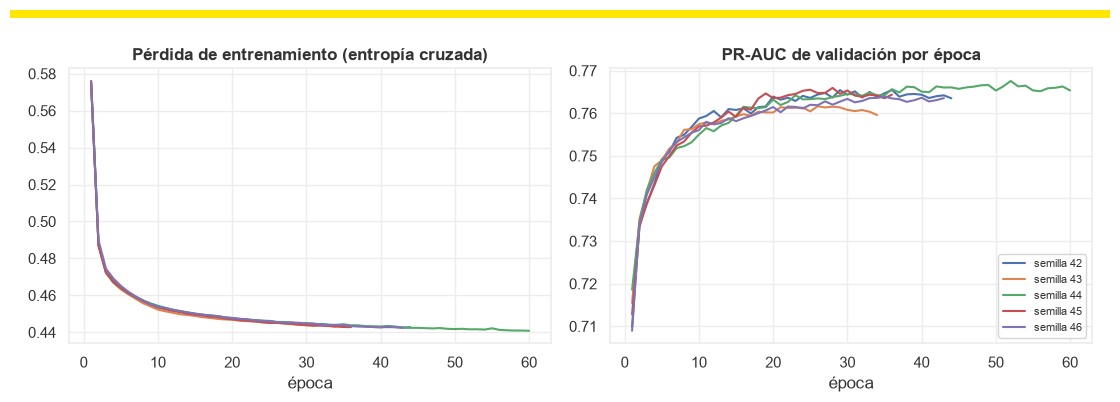

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for seed, history in histories.items():
    axes[0].plot(history.index, history["perdida_entrenamiento"], linewidth=1.5, label=f"semilla {seed}")
    axes[1].plot(history.index, history["pr_auc_validacion"], linewidth=1.5, label=f"semilla {seed}")
axes[0].set_title("Pérdida de entrenamiento (entropía cruzada)")
axes[0].set_xlabel("época")
axes[1].set_title("PR-AUC de validación por época")
axes[1].set_xlabel("época")
axes[1].legend(fontsize=8)
finish_figure(fig, "anfis_curvas_entrenamiento")

## 8. Evaluación sobre el conjunto de prueba reservado

In [12]:
def ranking_at_k(y_true, scores, fractions):
    """Precisión y exhaustividad al revisar solo la fracción de casos con mayor puntaje."""
    order = np.argsort(-np.asarray(scores), kind="stable")
    sorted_true = np.asarray(y_true)[order]
    prevalence = sorted_true.mean()
    rows = []
    for fraction in fractions:
        k = max(1, int(round(fraction * len(sorted_true))))
        hits = sorted_true[:k].sum()
        rows.append({
            "fraccion_revisada": fraction,
            "casos_revisados": k,
            "precision_en_k": hits / k,
            "recall_en_k": hits / sorted_true.sum(),
            "mejora_sobre_azar": (hits / k) / prevalence,
        })
    return pd.DataFrame(rows).set_index("fraccion_revisada")


def evaluate_seed(model, threshold=0.5):
    scores = predict_scores(model, X_test)
    predicted = (scores >= threshold).astype(int)
    metrics = {
        "pr_auc_validacion": average_precision_score(y_val, predict_scores(model, X_val)),
        "pr_auc": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
        "recall": recall_score(y_true, predicted),
        "precision": precision_score(y_true, predicted),
        "f1": f1_score(y_true, predicted),
        "tasa_falsos_positivos": ((predicted == 1) & (y_true == 0)).sum() / (y_true == 0).sum(),
    }
    for fraction, row in ranking_at_k(y_true, scores, RANKING_FRACTIONS).iterrows():
        metrics[f"recall_en_{fraction:.0%}"] = row["recall_en_k"]
        metrics[f"precision_en_{fraction:.0%}"] = row["precision_en_k"]
    return metrics


seed_metrics = pd.DataFrame({seed: evaluate_seed(model) for seed, model in models.items()})
seed_metrics.loc["segundos_entrenamiento"] = pd.Series({seed: info["segundos"] for seed, info in fit_info.items()})
seed_metrics.loc["mejor_epoca"] = pd.Series({seed: info["mejor_epoca"] for seed, info in fit_info.items()})
seed_metrics.columns.name = "semilla"

seed_summary = seed_metrics.copy()
seed_summary["media"] = seed_metrics.mean(axis=1)
seed_summary["desviacion"] = seed_metrics.std(axis=1)
seed_summary.round(4)

semilla,42,43,44,45,46,media,desviacion
pr_auc_validacion,0.7655,0.7617,0.7676,0.7660,0.7639,0.7649,0.0022
pr_auc,0.7524,0.7536,0.7516,0.7520,0.7546,0.7529,0.0012
roc_auc,0.8237,0.8232,0.8220,0.8228,0.8241,0.8231,0.0008
recall,0.5635,0.5583,0.5574,0.5726,0.5567,0.5617,0.0067
precision,0.7226,0.7283,0.7286,0.7140,0.7329,0.7253,0.0073
f1,0.6332,0.6321,0.6316,0.6355,0.6328,0.6330,0.0015
tasa_falsos_positivos,0.0982,0.0945,0.0942,0.1041,0.0920,0.0966,0.0047
recall_en_1%,0.0321,0.0321,0.0321,0.0321,0.0321,0.0321,0.0000
precision_en_1%,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000
recall_en_5%,0.1601,0.1601,0.1601,0.1601,0.1601,0.1601,0.0000


### Comparación con la red neuronal

Los valores del RNA son los de la corrida comprometida de `rna_shipment_loss.ipynb` (5 semillas, mismos conjuntos de entrenamiento, validación y prueba), tal como los registra `README.md`. Si ese notebook se vuelve a correr y cambian, hay que actualizar esta tabla.

In [13]:
RNA_REFERENCE = {
    "pr_auc": 0.7496,
    "roc_auc": 0.8241,
    "recall": 0.5339,
    "precision": 0.7568,
    "f1": 0.6259,
    "tasa_falsos_positivos": 0.0781,
    "recall_en_1%": 0.0321,
    "recall_en_5%": 0.1581,
    "recall_en_10%": 0.3019,
    "recall_en_20%": 0.5060,
    "precision_en_1%": 1.0000,
    "precision_en_5%": 0.9873,
    "precision_en_10%": 0.9421,
    "precision_en_20%": 0.7895,
}
comparison = pd.DataFrame({
    "ANFIS_media": seed_summary.loc[list(RNA_REFERENCE), "media"],
    "ANFIS_desviacion": seed_summary.loc[list(RNA_REFERENCE), "desviacion"],
    "RNA_media": pd.Series(RNA_REFERENCE),
})
comparison["diferencia_ANFIS_menos_RNA"] = comparison["ANFIS_media"] - comparison["RNA_media"]
comparison.round(4)

,ANFIS_media,ANFIS_desviacion,RNA_media,diferencia_ANFIS_menos_RNA
pr_auc,0.7529,0.0012,0.7496,0.0033
roc_auc,0.8231,0.0008,0.8241,-0.0010
recall,0.5617,0.0067,0.5339,0.0278
precision,0.7253,0.0073,0.7568,-0.0315
f1,0.6330,0.0015,0.6259,0.0071
tasa_falsos_positivos,0.0966,0.0047,0.0781,0.0185
recall_en_1%,0.0321,0.0000,0.0321,-0.0000
recall_en_5%,0.1601,0.0000,0.1581,0.0020
recall_en_10%,0.3107,0.0007,0.3019,0.0088
recall_en_20%,0.5030,0.0023,0.5060,-0.0030


### Modelo de referencia

Se elige la semilla con mejor PR-AUC de **validación**, nunca de prueba, y sobre ella se hace la evaluación detallada.

In [14]:
reference_seed = int(seed_metrics.loc["pr_auc_validacion"].idxmax())
model = models[reference_seed]
proba = predict_scores(model, X_test)
print(f"semilla de referencia: {reference_seed}")

roc_auc = roc_auc_score(y_true, proba)
avg_precision = average_precision_score(y_true, proba)
print(f"ROC AUC: {roc_auc:.4f}")
print(f"Precisión promedio (PR-AUC): {avg_precision:.4f}")

semilla de referencia: 44
ROC AUC: 0.8220
Precisión promedio (PR-AUC): 0.7516


In [15]:
y_pred = (proba >= 0.5).astype(int)
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=["no perdido", "perdido"]))

[[13140  1367]
 [ 2913  3669]]
              precision    recall  f1-score   support

  no perdido       0.82      0.91      0.86     14507
     perdido       0.73      0.56      0.63      6582

    accuracy                           0.80     21089
   macro avg       0.77      0.73      0.75     21089
weighted avg       0.79      0.80      0.79     21089



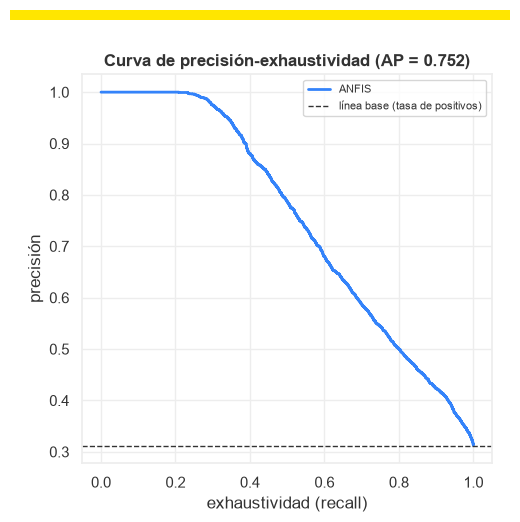

In [16]:
precision, recall, _ = precision_recall_curve(y_true, proba)
fig, ax = plt.subplots(figsize=(5, 5.2))
ax.plot(recall, precision, color=ML_BLUE, linewidth=2, label="ANFIS")
ax.axhline(y_true.mean(), color=COLOR_REFERENCE, linestyle="--", linewidth=1, label="línea base (tasa de positivos)")
ax.set_xlabel("exhaustividad (recall)")
ax.set_ylabel("precisión")
ax.set_title(f"Curva de precisión-exhaustividad (AP = {avg_precision:.3f})")
ax.legend(fontsize=8)
finish_figure(fig, "anfis_curva_precision_exhaustividad")

### Calidad de la priorización

In [17]:
ranking_at_k(y_true, proba, RANKING_FRACTIONS).round(3)

,casos_revisados,precision_en_k,recall_en_k,mejora_sobre_azar
fraccion_revisada,,,,
0.01,211,1.000,0.032,3.204
0.05,1054,1.000,0.160,3.204
0.10,2109,0.969,0.311,3.105
0.20,4218,0.785,0.503,2.514


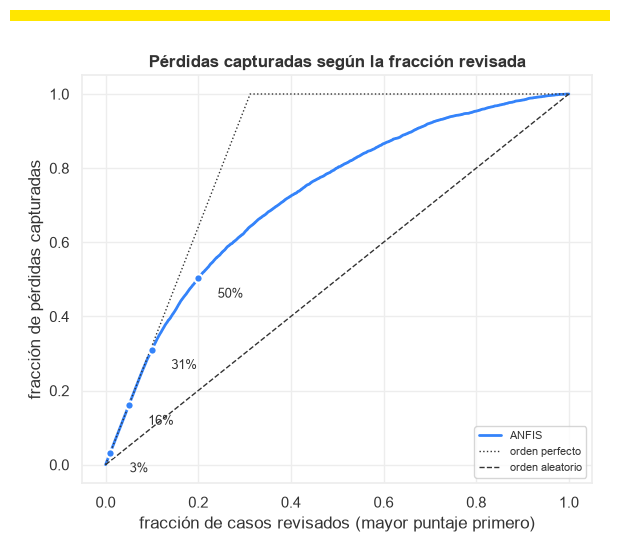

In [18]:
order = np.argsort(-proba, kind="stable")
captured = np.cumsum(y_true[order]) / y_true.sum()
fraction_reviewed = np.arange(1, len(captured) + 1) / len(captured)
prevalence = y_true.mean()

fig, ax = plt.subplots(figsize=(6, 5.4))
ax.plot(fraction_reviewed, captured, color=ML_BLUE, linewidth=2, label="ANFIS")
ax.plot([0, prevalence, 1], [0, 1, 1], color=COLOR_REFERENCE, linestyle=":", linewidth=1, label="orden perfecto")
ax.plot([0, 1], [0, 1], color=COLOR_REFERENCE, linestyle="--", linewidth=1, label="orden aleatorio")
for fraction in RANKING_FRACTIONS:
    recall_at_fraction = captured[max(1, int(round(fraction * len(captured)))) - 1]
    ax.scatter([fraction], [recall_at_fraction], color=ML_BLUE, s=36, zorder=3, edgecolor=ML_SURFACE, linewidth=1.5)
    ax.annotate(
        f"{recall_at_fraction:.0%}", (fraction, recall_at_fraction), textcoords="offset points", xytext=(14, -14), fontsize=9
    )
ax.set_xlabel("fracción de casos revisados (mayor puntaje primero)")
ax.set_ylabel("fracción de pérdidas capturadas")
ax.set_title("Pérdidas capturadas según la fracción revisada")
ax.legend(loc="lower right", fontsize=8)
finish_figure(fig, "anfis_curva_ganancia")

## 9. Proyección a la prevalencia real

Misma lógica que en el notebook RNA: de la muestra caso-control solo la exhaustividad y la tasa de falsos positivos se trasladan a producción sin cambios; con ellas y `REAL_PREVALENCE` (estimación del equipo, no medida aquí) se reconstruye cuántos envíos habría que revisar y cuántas pérdidas reales se capturarían. Es una proyección, y hereda la duda sobre si los negativos muestreados representan a los reales.

In [19]:
def project_to_prevalence(y_true, scores, thresholds, prevalence):
    """Reconstruye el escenario operativo a partir de las dos tasas que no dependen de la prevalencia."""
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    rows = []
    for name, threshold in thresholds.items():
        flagged = scores >= threshold
        recall = flagged[y_true == 1].mean()
        false_positive_rate = flagged[y_true == 0].mean()
        reviewed = prevalence * recall + (1 - prevalence) * false_positive_rate
        precision = prevalence * recall / reviewed
        rows.append({
            "umbral": name,
            "puntaje_minimo": threshold,
            "exhaustividad": recall,
            "tasa_falsos_positivos": false_positive_rate,
            "fraccion_revisada_real": reviewed,
            "precision_real": precision,
            "revisados_por_perdida": 1 / precision,
            "mejora_sobre_azar_real": precision / prevalence,
        })
    return pd.DataFrame(rows).set_index("umbral")


sorted_scores = np.sort(proba)[::-1]
thresholds = {"0,5": 0.5}
for fraction in RANKING_FRACTIONS:
    k = max(1, int(round(fraction * len(sorted_scores))))
    thresholds[f"{fraction:.0%} de la muestra"] = sorted_scores[k - 1]

project_to_prevalence(y_true, proba, thresholds, REAL_PREVALENCE).round(4)

,puntaje_minimo,exhaustividad,tasa_falsos_positivos,fraccion_revisada_real,precision_real,revisados_por_perdida,mejora_sobre_azar_real
umbral,,,,,,,
"0,5",0.5000,0.5574,0.0942,0.0947,0.0059,169.8755,5.8867
1% de la muestra,1.0000,0.0321,0.0000,0.0000,1.0000,1.0000,1000.0000
5% de la muestra,0.9996,0.1601,0.0000,0.0002,1.0000,1.0000,1000.0000
10% de la muestra,0.8902,0.3105,0.0045,0.0048,0.0649,15.4138,64.8770
20% de la muestra,0.5788,0.5029,0.0626,0.0630,0.0080,125.3379,7.9784


## 10. Lectura difusa del modelo de referencia

Esta es la razón de ser de un sistema difuso frente a una red neuronal opaca: sus parámetros se pueden leer.

- **Funciones de pertenencia**: cada curva es la gaussiana aprendida por una regla para una variable, en la escala estandarizada de entrenamiento (0 es la media, ±1 una desviación). Una regla con centro positivo en `VALOR_TOTAL_USD` se activa con envíos caros; un ancho grande significa que la variable casi no discrimina para esa regla.
- **Base de reglas**: cada regla se describe por la posición de su centro en cada variable, traducida a una etiqueta lingüística según el cuantil de entrenamiento en el que cae (`bajo` por debajo del cuantil 0,33, `alto` por encima del 0,67, `medio` entre ambos), junto con cuántas filas de prueba domina (es la regla de mayor activación) y qué tasa de pérdida tienen esas filas.
- **Importancia por permutación**: caída de la PR-AUC de prueba al barajar cada variable. Mide de qué depende el modelo, no causalidad; las variables codificadas por tasa heredan la advertencia del notebook RNA sobre `DOM_DOMAIN_ID`.

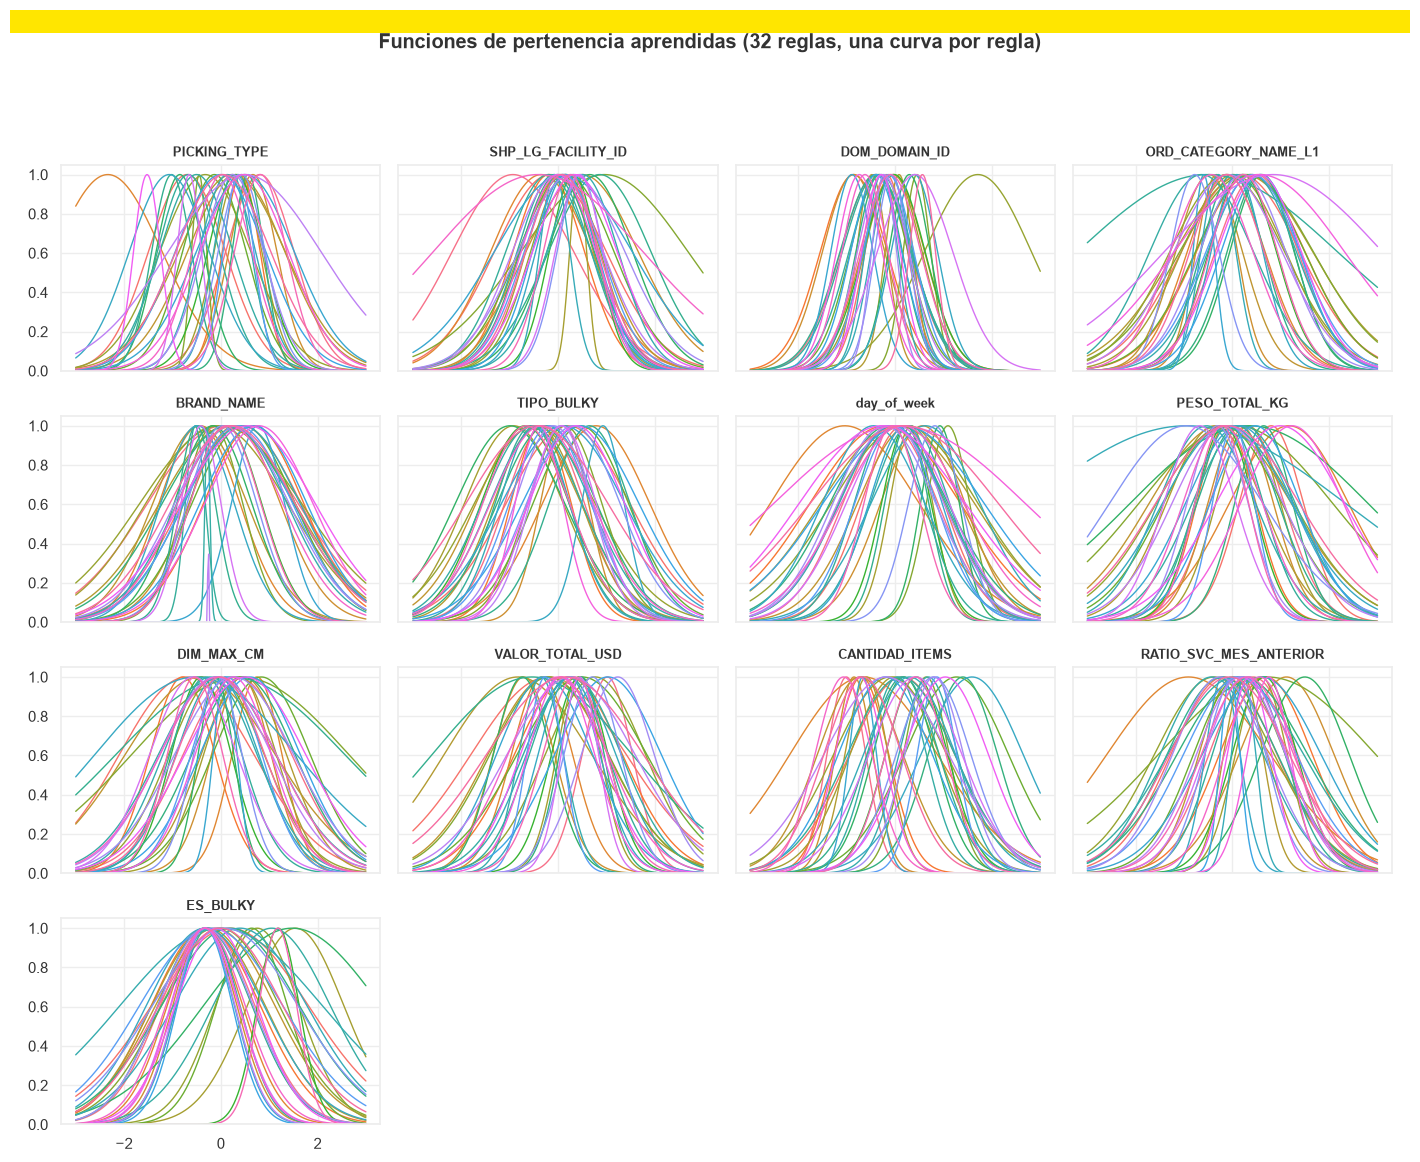

In [20]:
centers = model.centers.detach().numpy()
widths = torch.exp(model.log_widths).detach().numpy()
feature_names = encoder.feature_names
grid = np.linspace(-3, 3, 300)

n_cols = 4
n_rows = int(np.ceil(len(feature_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 2.9 * n_rows), sharex=True, sharey=True)
rule_colors = sns.color_palette("husl", N_RULES)
for ax, (i, feature) in zip(axes.flat, enumerate(feature_names)):
    for r in range(N_RULES):
        ax.plot(grid, np.exp(-0.5 * ((grid - centers[r, i]) / widths[r, i]) ** 2), color=rule_colors[r], linewidth=1)
    ax.set_title(feature, fontsize=9)
    ax.set_ylim(0, 1.05)
for ax in axes.flat[len(feature_names):]:
    ax.axis("off")
fig.suptitle(f"Funciones de pertenencia aprendidas ({N_RULES} reglas, una curva por regla)", fontweight="bold")
finish_figure(fig, "anfis_funciones_pertenencia", top=0.93)

In [21]:
LINGUISTIC_LABELS = ["bajo", "medio", "alto"]
train_quantiles = np.quantile(X_train, [1 / 3, 2 / 3], axis=0)


def linguistic(center, feature_index):
    low, high = train_quantiles[:, feature_index]
    return "bajo" if center < low else "alto" if center > high else "medio"


with torch.no_grad():
    test_firing = model.firing(torch.as_tensor(X_test)).numpy()
dominant_rule = test_firing.argmax(axis=1)

rule_table = pd.DataFrame(
    {feature: [linguistic(centers[r, i], i) for r in range(N_RULES)] for i, feature in enumerate(feature_names)}
)
rule_table.index.name = "regla"
rule_table["filas_prueba_dominadas"] = pd.Series(dominant_rule).value_counts().reindex(range(N_RULES), fill_value=0)
rule_table["tasa_perdida_dominadas"] = [
    y_true[dominant_rule == r].mean() if (dominant_rule == r).any() else np.nan for r in range(N_RULES)
]
rule_table["sesgo_consecuente"] = model.consequent_bias.detach().numpy()
rule_table.sort_values("tasa_perdida_dominadas", ascending=False).round(3)

,PICKING_TYPE,SHP_LG_FACILITY_ID,DOM_DOMAIN_ID,ORD_CATEGORY_NAME_L1,BRAND_NAME,TIPO_BULKY,day_of_week,PESO_TOTAL_KG,DIM_MAX_CM,VALOR_TOTAL_USD,CANTIDAD_ITEMS,RATIO_SVC_MES_ANTERIOR,ES_BULKY,filas_prueba_dominadas,tasa_perdida_dominadas,sesgo_consecuente
regla,,,,,,,,,,,,,,,,
8,bajo,medio,alto,medio,medio,bajo,medio,medio,medio,alto,alto,bajo,alto,1562,0.957,1.396
13,alto,medio,medio,alto,alto,bajo,medio,alto,alto,alto,alto,alto,alto,174,0.707,0.477
10,bajo,medio,medio,alto,alto,alto,medio,medio,alto,alto,alto,alto,alto,1153,0.670,-0.209
22,medio,medio,medio,alto,alto,bajo,medio,medio,medio,medio,alto,alto,alto,119,0.630,1.102
17,bajo,alto,medio,alto,alto,bajo,medio,bajo,medio,medio,alto,bajo,alto,529,0.590,0.532
24,bajo,medio,medio,alto,alto,bajo,medio,medio,medio,alto,alto,bajo,alto,172,0.529,0.301
23,alto,alto,medio,bajo,medio,medio,alto,bajo,medio,alto,alto,alto,alto,23,0.522,0.226
18,bajo,medio,medio,medio,alto,bajo,medio,bajo,medio,medio,alto,alto,alto,170,0.482,0.165
12,bajo,alto,alto,alto,medio,bajo,alto,medio,medio,bajo,alto,alto,alto,11,0.455,-0.223


,caida_pr_auc,desviacion
DOM_DOMAIN_ID,0.2474,0.0024
CANTIDAD_ITEMS,0.0898,0.0022
SHP_LG_FACILITY_ID,0.0797,0.0031
PESO_TOTAL_KG,0.0419,0.0015
BRAND_NAME,0.0396,0.0021
PICKING_TYPE,0.0138,0.0002
ORD_CATEGORY_NAME_L1,0.0097,0.0009
DIM_MAX_CM,0.0095,0.0003
VALOR_TOTAL_USD,0.0067,0.0004
ES_BULKY,0.0051,0.0002


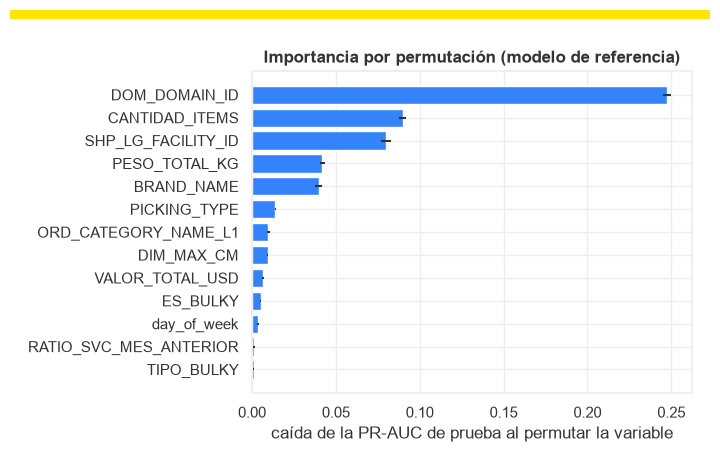

In [22]:
def permutation_importance(model, X, y, seed=RANDOM_STATE, repeats=3):
    rng = np.random.default_rng(seed)
    baseline = average_precision_score(y, predict_scores(model, X))
    rows = {}
    for i, feature in enumerate(feature_names):
        drops = []
        for _ in range(repeats):
            shuffled = X.copy()
            shuffled[:, i] = rng.permutation(shuffled[:, i])
            drops.append(baseline - average_precision_score(y, predict_scores(model, shuffled)))
        rows[feature] = {"caida_pr_auc": np.mean(drops), "desviacion": np.std(drops, ddof=1)}
    return pd.DataFrame(rows).T.sort_values("caida_pr_auc", ascending=False)


importance = permutation_importance(model, X_test, y_true)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance.index[::-1], importance["caida_pr_auc"][::-1], color=ML_BLUE, xerr=importance["desviacion"][::-1], ecolor=ML_INK)
ax.set_xlabel("caída de la PR-AUC de prueba al permutar la variable")
ax.set_title("Importancia por permutación (modelo de referencia)")
finish_figure(fig, "anfis_importancia_permutacion")
importance.round(4)

## 11. Limitaciones y próximos pasos

- **Mismo sesgo de extracción que el RNA**: el ANFIS aprende sobre los mismos datos caso-control, con los mismos artefactos documentados en el notebook RNA (`DOM_DOMAIN_ID` incluido). Un modelo distinto no corrige una muestra sesgada; las reglas de re-extracción de `README.md` siguen vigentes.
- **Precisión perfecta en el tope del ranking**: igual que el RNA, el ANFIS alcanza precisión 1,000 en el 1 % y el 5 % superior de la prueba y tasa de falsos positivos 0 en esos umbrales de la proyección. Con `DOM_DOMAIN_ID` como variable dominante por permutación y seis dominios 100 % perdidos en los datos (problema abierto documentado en `CLAUDE.md`), lo más probable es que esa precisión sea el artefacto de taxonomía y no señal real; no debe presentarse como tal hasta investigar esos dominios.
- **La codificación por tasa mueve parte del aprendizaje fuera del modelo difuso**: las categóricas entran ya resumidas en una tasa de pérdida, así que la lectura "regla difusa sobre `BRAND_NAME` alto" significa "marcas con alta tasa histórica de pérdida", no una marca concreta. Es el precio de usar gaussianas sobre variables con miles de categorías; una alternativa es agrupar categorías a mano en conjuntos difusos con nombre.
- **Categorías no vistas**: la tabla de la sección 4 muestra que una fracción importante de las filas de prueba trae un `BRAND_NAME` que no aparece en entrenamiento y entra con la tasa global. Para esas filas la marca no aporta nada, y en producción, con marcas nuevas cada mes, la fracción será mayor. Un agrupamiento de marcas (por vendedor, por categoría) sería más estable que la marca individual.
- **Interpretabilidad acotada**: con más de una decena de variables por regla, la base de reglas se lee por sus etiquetas lingüísticas dominantes, no como reglas cortas de libro. Reducir variables o imponer anchos grandes (regularización) daría reglas más legibles a cambio de rendimiento; es un tradeoff a decidir según el uso.
- **Hiperparámetros apenas explorados**: solo se seleccionó el número de reglas. Tasa de aprendizaje, suavizado del previo (`TARGET_ENCODING_PRIOR_WEIGHT`), ancho mínimo y pertenencias no gaussianas (campana generalizada, triangulares) quedan como trabajo futuro, siempre seleccionados por validación.
- **Puntajes no calibrados a producción**: como en el RNA, el umbral 0,5 y los puntajes son de la escala de la muestra; cualquier uso operativo pasa por la proyección de la sección 9 y por una medición real de la prevalencia.